# PetFinder Adoption Speed Prediction
## Multi-Modal Machine Learning Project (Tabular, Text, Images)
**Goal**: Predict the speed of pet adoption (`AdoptionSpeed`: 0 to 4) using shelter profile data.
**Metric**: Quadratic Weighted Kappa (QWK).

**import libs**

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

**load datasets**

In [56]:
train_df = pd.read_csv("PetFinder-Project-Dataset/train/train.csv")
test_df = pd.read_csv("PetFinder-Project-Dataset/test/test.csv")

breed = pd.read_csv("PetFinder-Project-Dataset/breed_labels.csv")
color = pd.read_csv("PetFinder-Project-Dataset/color_labels.csv")
state = pd.read_csv("PetFinder-Project-Dataset/state_labels.csv")

## 1. Exploratory Data Analysis (EDA)

### 1.1 Target Variable Analysis (`AdoptionSpeed`)
In PetFinder, `AdoptionSpeed` is an ordinal target variable categorized into 5 distinct time buckets:
* **0**: Adopted on the same day as listed.
* **1**: Adopted within 1–7 days (first week).
* **2**: Adopted within 8–30 days (first month).
* **3**: Adopted within 31–90 days (first quarter).
* **4**: Not adopted after 100 days (long-term shelter stay).

**Key Findings**:
* **Class Imbalance**: Class 0 is heavily under-represented (only 2.73% of the dataset), while Classes 2 and 4 constitute over 54% combined.
* **Validation Strategy**: Because of this imbalance, standard random K-Fold cross-validation will fail on minority folds. We must use **Stratified K-Fold** to maintain the 2.73% ratio across all training/validation splits.

               Count  Percentage (%)
AdoptionSpeed                       
0                410            2.73
1               3090           20.61
2               4037           26.93
3               3259           21.74
4               4197           27.99


C:\Users\a\AppData\Local\Temp\ipykernel_4956\646846617.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_summary.index, y=dist_summary['Count'], palette='viridis')


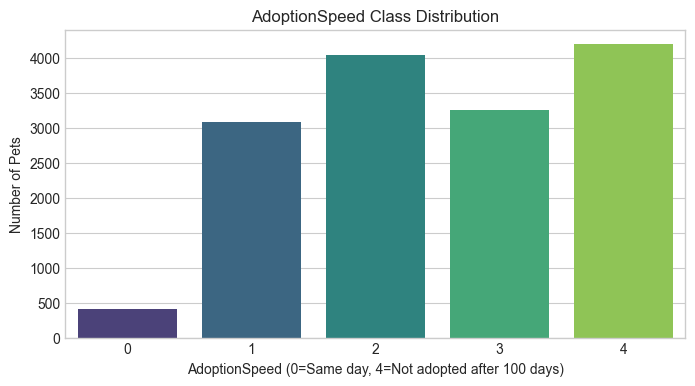

In [57]:
speed_counts = train_df["AdoptionSpeed"].value_counts().sort_index()
speed_pcts = (speed_counts/len(train_df) * 100).round(2)


dist_summary = pd.DataFrame({'Count': speed_counts, 'Percentage (%)': speed_pcts})
print(dist_summary)
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(8, 4))
sns.barplot(x=dist_summary.index, y=dist_summary['Count'], palette='viridis')
plt.title("AdoptionSpeed Class Distribution")
plt.xlabel("AdoptionSpeed (0=Same day, 4=Not adopted after 100 days)")
plt.ylabel("Number of Pets")
plt.show()

### 1.2 Data Cleaning & Feature Transformation
Real-world shelter databases frequently use sentinel integers (e.g., `0` for none) rather than standard SQL `NULL` or pandas `NaN` values:
1. **Breeds**: Pets can be purebred (`Breed2 == 0`) or mixed (`Breed2 > 0`). We engineer a binary flag `IsPurebred`.
2. **Colors**: A pet has up to 3 colors. We map `ColorID` using the lookup table and compute `NumColors` (count of non-zero color fields).
3. **Names**: We distinguish between genuine names and shelter placeholder strings (e.g., *"No Name"*, *"Puppy"*, *"Kitten"*), generating the binary feature `HasName`.
4. **Fees**: Pet adoption fee is binary-flagged with `IsFree` (`Fee == 0`).

In [58]:
df = train_df.copy()
df["HasName"] = df["Name"].notna() & (~df["Name"].astype(str).str.lower().isin(['no name','unnamed','no name yet', 'none', 'baby', 'puppy', 'kitten','name']))
df['HasName'] = df['HasName'].astype(int)

df["IsFree"] = (df['Fee'] == 0).astype(int)
df['IsPureBreed'] = (df["Breed2"] == 0).astype(int)

breed_map = breed.set_index("BreedID")['BreedName'].to_dict()

df['Breed1'] = df["Breed1"].map(breed_map).fillna("unknown")
df['Breed2'] = df["Breed2"].map(breed_map).fillna("unknown")

color_map = color.set_index('ColorID')['ColorName'].to_dict()

df['Color1_name'] = df['Color1'].map(color_map).fillna('None')
df['Color2_name'] = df['Color2'].map(color_map).fillna('None')
df['Color3_name'] = df['Color3'].map(color_map).fillna('None')

df['NumColors'] = (df['Color1'] > 0).astype(int) + (df['Color2'] > 0).astype(int) + (df['Color3'] > 0).astype(int)

state_map = state.set_index("StateID")["StateName"].to_dict()

df['State'] = df['State'].map(state_map).fillna("unknown")

df['Description'] = df['Description'].fillna('')
df['DescLength'] = df['Description'].str.len()
df['DescWordCount'] = df['Description'].apply(lambda x: len(str(x).split()))

In [59]:
# def integrate_lookups_and_clean(df:pd.DataFrame,breed:pd.DataFrame,color:pd.DataFrame,state:pd.DataFrame) -> pd.DataFrame:
    
#     df = df.copy()
#     df["HasName"] = df["Name"].notna() & (~df["Name"].astype(str).str.lower().isin(['no name','unnamed','no name yet']))
#     df['HasName'] = df['HasName'].astype(int)

    

### 1.3 Bivariate Feature Relationships with Adoption Speed
* **Age vs. Adoption Speed**: Younger animals (kittens and puppies aged 1–3 months) have a significantly higher probability of rapid adoption (Classes 0 & 1). As age increases, adoption probability decays sharply into Class 4.
* **Naming**: Animals with human-readable names show consistently higher adoption velocities than unnamed animals, reflecting rescuer engagement and emotional bonding.

C:\Users\a\AppData\Local\Temp\ipykernel_4956\3544907449.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='AdoptionSpeed', y='Age', ax=axes[1], showfliers=False, palette='coolwarm')


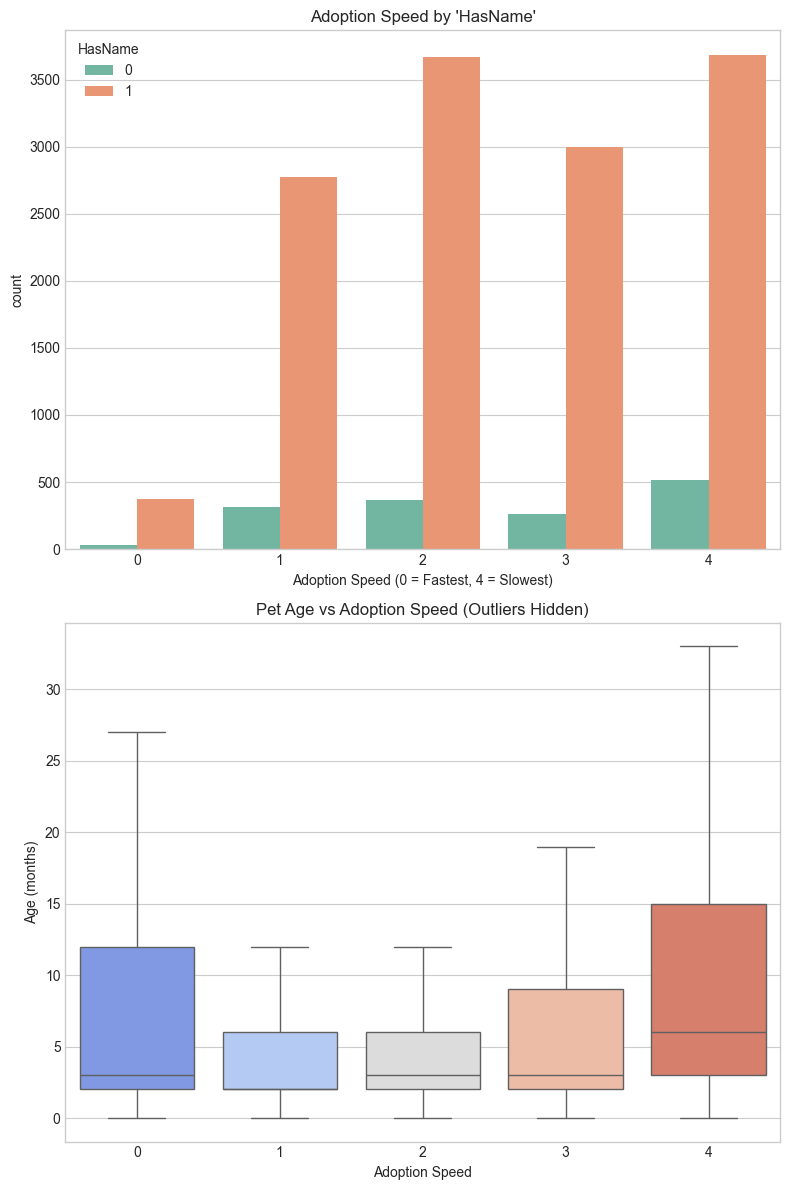

In [54]:
fig, axes = plt.subplots(2,1, figsize=(8, 12))

# Plot 1: HasName vs AdoptionSpeed
sns.countplot(data=df, x='AdoptionSpeed', hue='HasName', ax=axes[0], palette='Set2')
axes[0].set_title("Adoption Speed by 'HasName'")
axes[0].set_xlabel("Adoption Speed (0 = Fastest, 4 = Slowest)")

# Plot 2: Age vs AdoptionSpeed
sns.boxplot(data=df, x='AdoptionSpeed', y='Age', ax=axes[1], showfliers=False, palette='coolwarm')
axes[1].set_title("Pet Age vs Adoption Speed (Outliers Hidden)")
axes[1].set_xlabel("Adoption Speed")
axes[1].set_ylabel("Age (months)")

plt.tight_layout()
plt.show()

## 2. Text Feature Engineering (NLP on `Description`)
The pet's `Description` contains qualitative details about health, temperament, vaccination history, and urgency.
We extract:
1. **Metadata Statistics**: Word count, character length, exclamation mark count (urgency indicator).
2. **TF-IDF (Term Frequency - Inverse Document Frequency)**: Captures key discriminative words (e.g., *"urgent"*, *"playful"*, *"trained"*, *"rescued"*).
3. **Dimensionality Reduction (TruncatedSVD / LSA)**: Compresses the high-dimensional sparse TF-IDF matrix into 50 dense topic components suitable for tree-based classifiers.